# Used Car Price Prediction — Mini Project

Regression project using the classic CarDekho dataset. Download `car data.csv` from [Kaggle](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho) and place it beside this notebook.

Target: `Selling_Price`. Data prices are retained in their original units. Do not interpret results until verifying the dataset's currency/unit.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

DATA_PATH = Path("cardekho_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("cardekho_dataset.csv")
raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (15411, 14)


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [5]:
df = raw.copy()
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
rename = {"price":"selling_price", "km_driven":"km_driven", "fuel_type":"fuel", "car_name":"name"}
df = df.rename(columns={c: rename[c] for c in df.columns if c in rename})
if "selling_price" not in df: raise ValueError("Missing Selling_Price/Price target column")
df["vehicle_age"] = pd.Timestamp.now().year - pd.to_numeric(df["year"], errors="coerce") if "year" in df else pd.to_numeric(df.get("vehicle_age"), errors="coerce")
for col in ["present_price","km_driven","owner"]:
    if col not in df: df[col] = np.nan
for col in ["fuel","seller_type","transmission","name"]:
    if col not in df: df[col] = "Unknown"
for col in ["selling_price","present_price","km_driven","owner","vehicle_age"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.dropna(subset=["selling_price"]).query("selling_price > 0").drop_duplicates().reset_index(drop=True)
print("Clean shape:", df.shape); display(df.isna().sum().to_frame("missing")); display(df.describe(include="all").T)

Clean shape: (15411, 17)


,missing
unnamed:_0,0
name,0
brand,0
model,0
vehicle_age,0
km_driven,0
seller_type,0
fuel,0
transmission_type,0
mileage,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unnamed:_0,15411.0,NaN,NaN,NaN,9811.857699,5643.418542,0.0,4906.5,9872.0,14668.5,19543.0
name,15411,121,Hyundai i20,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,15411,32,Maruti,4992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,15411,120,i20,906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_age,15411.0,NaN,NaN,NaN,6.036338,3.013291,0.0,4.0,6.0,8.0,29.0
km_driven,15411.0,NaN,NaN,NaN,55616.480631,51618.548422,100.0,30000.0,50000.0,70000.0,3800000.0
seller_type,15411,3,Dealer,9539,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,15411,5,Petrol,7643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission_type,15411,2,Manual,12225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,15411.0,NaN,NaN,NaN,19.701151,4.171265,4.0,17.0,19.67,22.7,33.54


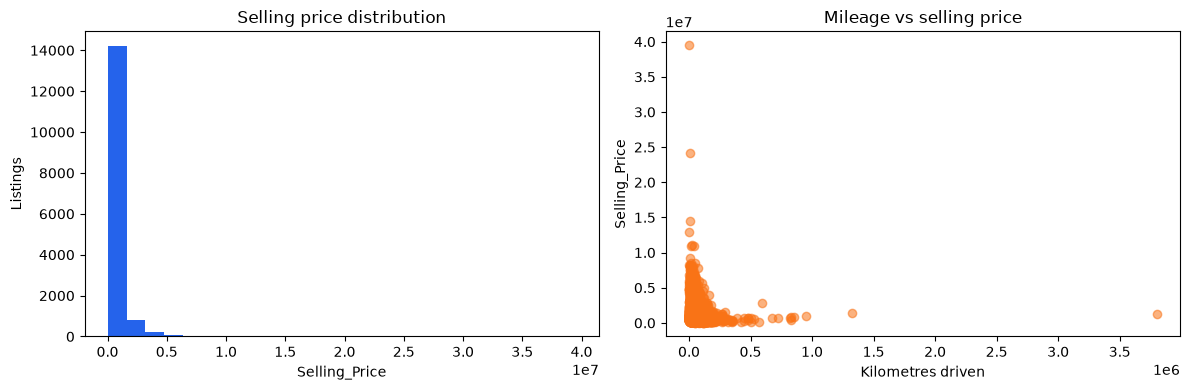

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.selling_price, bins=25, color="#2563eb"); ax[0].set(title="Selling price distribution", xlabel="Selling_Price", ylabel="Listings")
ax[1].scatter(df.km_driven, df.selling_price, alpha=.55, color="#f97316"); ax[1].set(title="Mileage vs selling price", xlabel="Kilometres driven", ylabel="Selling_Price")
plt.tight_layout()

In [7]:
features = ["vehicle_age","km_driven","present_price","owner","fuel","seller_type","transmission","name"]
target = "selling_price"
X, y = df[features], df[target]
numeric = ["vehicle_age","km_driven","present_price","owner"]
categorical = ["fuel","seller_type","transmission","name"]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer",SimpleImputer(strategy="median",add_indicator=True)),("scale",StandardScaler())]),numeric),
    ("cat", Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical)
])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
print("Train:",len(X_train),"Test:",len(X_test))

Train: 12328 Test: 3083


In [8]:
candidates = {
 "Random Forest": RandomForestRegressor(n_estimators=300,max_features=.9,random_state=42),
 "Extra Trees": ExtraTreesRegressor(n_estimators=300,max_features=.9,random_state=42),
 "Gradient Boosting": GradientBoostingRegressor(n_estimators=150,learning_rate=.04,max_depth=2,random_state=42)
}
rows=[]; fitted={}
for name, estimator in candidates.items():
    pipe=Pipeline([("preprocess",preprocessor),("regressor",estimator)])
    pipe.fit(X_train,y_train); pred=pipe.predict(X_test)
    rows.append({"Model":name,"MAE":mean_absolute_error(y_test,pred),"RMSE":mean_squared_error(y_test,pred)**.5,"R2":r2_score(y_test,pred)})
    fitted[name]=pipe
comparison=pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(comparison.style.format({"MAE":"{:,.2f}","RMSE":"{:,.2f}","R2":"{:.3f}"}))
best_name=comparison.loc[0,"Model"]; best_model=fitted[best_name]
print("Selected:",best_name)

c:\Users\ELCOT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['present_price' 'owner']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\ELCOT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['present_price' 'owner']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\ELCOT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['present_price' 'owner']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\ELCOT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without a

,Model,MAE,RMSE,R2
0,Extra Trees,"118,321.94","338,214.72",0.848
1,Random Forest,"122,132.14","360,640.92",0.827
2,Gradient Boosting,"348,181.31","659,276.39",0.423


Selected: Extra Trees


c:\Users\ELCOT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['present_price' 'owner']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


MAE:  118,321.942
RMSE: 338,214.720
R²:   0.848


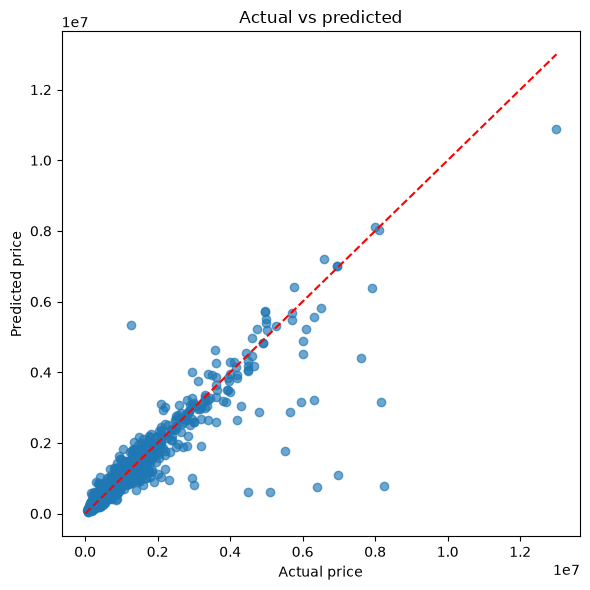

In [9]:
pred=best_model.predict(X_test)
print(f"MAE:  {mean_absolute_error(y_test,pred):,.3f}")
print(f"RMSE: {mean_squared_error(y_test,pred)**.5:,.3f}")
print(f"R²:   {r2_score(y_test,pred):.3f}")
fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(y_test,pred,alpha=.65); lim=max(y_test.max(),pred.max()); ax.plot([0,lim],[0,lim],"r--"); ax.set(xlabel="Actual price",ylabel="Predicted price",title="Actual vs predicted")
plt.tight_layout()

In [10]:
# Example prediction from a real row structure; change values to explore
sample = X_test.iloc[[0]].copy()
display(sample)
print("Predicted price:", round(float(best_model.predict(sample)[0]), 2))
joblib.dump({"model":best_model,"features":features,"model_name":best_name},"used_car_price_model.joblib")
print("Saved used_car_price_model.joblib")

,vehicle_age,km_driven,present_price,owner,fuel,seller_type,transmission,name
3334,12,73000,NaN,NaN,Petrol,Dealer,Unknown,Hyundai i10


c:\Users\ELCOT\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['present_price' 'owner']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Predicted price: 246981.67
Saved used_car_price_model.joblib


## Streamlit application
Run from the project folder after installing `requirements.txt`: `streamlit run app.py`. Upload the same Kaggle CSV in the app or place it next to `app.py`. The app trains and compares models at launch, then accepts vehicle information and returns an estimate. Prices are shown in the CSV's target units.